# Fig. 1 Seed-Window Stability

Generate the seed-window stability figure directly from `stage1_seed_grid_summary.csv`.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


ROOT = Path.cwd()
OUT_DIR = ROOT / "paper_figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcdefaults()
plt.rcParams.update({
    "savefig.dpi": 300,
    "figure.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.labelsize": 10.2,
    "axes.titlesize": 11.2,
    "xtick.labelsize": 8.6,
    "ytick.labelsize": 8.6,
    "legend.fontsize": 8,
    "axes.linewidth": 1.0,
})

LINE_STYLES = {
    "Pearson": dict(color="#0984e3", marker="o", linestyle="dashdot", linewidth=2.4, markersize=7.5),
    "Spearman": dict(color="#fdcb6e", marker="s", linestyle="dashed", linewidth=2.4, markersize=7.5),
    "Top-20 overlap": dict(color="#00b894", marker="^", linestyle="solid", linewidth=2.6, markersize=7.5),
}


def style_line_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", width=0.9, length=3.5, labelsize=8.6, pad=2)
    ax.set_axisbelow(True)


seed_df = pd.read_csv(ROOT.parent / "results" / "grid_search" / "stage1_seed_grid_summary.csv").sort_values("n_seed_windows")

fig, ax = plt.subplots(figsize=(3.45, 2.55))
x = np.arange(len(seed_df))
xlabels = seed_df["n_seed_windows"].astype(int).astype(str).tolist()

series = {
    "Pearson": "pearson_to_ref",
    "Spearman": "spearman_to_ref",
    "Top-20 overlap": "top20_overlap_ratio",
}

for label, col in series.items():
    ax.plot(
        x,
        seed_df[col].to_numpy(),
        label=label,
        markerfacecolor="none",
        markeredgewidth=1.4,
        **LINE_STYLES[label],
    )

ax.set_xlabel("n_seed_windows")
ax.set_ylabel("Similarity to reference")
ax.set_xticks(x)
ax.set_xticklabels(xlabels)
ax.set_xlim(-0.20, len(x) - 0.80)
ax.set_ylim(0.72, 1.02)
ax.set_yticks([0.75, 0.80, 0.85, 0.90, 0.95, 1.00])
style_line_axis(ax)
ax.legend(loc="lower right", frameon=True, handlelength=2.2, borderpad=0.25)

fig.tight_layout()
fig.savefig(OUT_DIR / "fig1_seed_window_stability.pdf", bbox_inches="tight")
plt.show()
print(OUT_DIR / "fig1_seed_window_stability.pdf")

# Fig. 2 Validation Results

Generate one native `1x3` figure for the Full-LPCMCI comparison, VAR core recovery metrics, and false-positive behavior.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, NullLocator


ROOT = Path.cwd()
OUT_DIR = ROOT / "paper_figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcdefaults()
plt.rcParams.update({
    "savefig.dpi": 300,
    "figure.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "font.family": "DejaVu Sans",
    "font.size": 8.4,
    "axes.labelsize": 9.8,
    "axes.titlesize": 11.0,
    "xtick.labelsize": 7.6,
    "ytick.labelsize": 7.6,
    "legend.fontsize": 5.7,
    "axes.linewidth": 0.9,
})


def to_float_series(s):
    return (
        s.astype(str)
        .str.replace("%", "", regex=False)
        .str.replace("x", "", regex=False)
        .str.replace("×", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip()
        .astype(float)
    )


def style_line_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", width=0.85, length=3.0, labelsize=7.8, pad=2)
    ax.set_axisbelow(True)


def plot_open_line(ax, x, y, label, color, marker, linestyle="solid", linewidth=2.1, markersize=5.6):
    ax.plot(
        x,
        y,
        label=label,
        color=color,
        marker=marker,
        linestyle=linestyle,
        linewidth=linewidth,
        markersize=markersize,
        markerfacecolor="none",
        markeredgecolor=color,
        markeredgewidth=1.25,
    )


# ---------- (a) Full-LPCMCI comparison across ROI sizes ----------
paper_df = pd.read_csv(ROOT.parent / "results" / "tables" / "lagged_hypothesis" / "lagged_hypothesis_hop2_paper_table.csv")
raw_df = pd.read_csv(ROOT.parent / "results" / "tables" / "lagged_hypothesis" / "lagged_hypothesis_hop2_raw.csv")
roi_df = paper_df.merge(
    raw_df[["roi_size", "full_time_sec", "screen_local_time_sec"]],
    left_on="ROI size",
    right_on="roi_size",
    how="left",
)
roi_df["Relative runtime"] = 100.0 * roi_df["screen_local_time_sec"] / roi_df["full_time_sec"]

# ---------- (b)(c) Controlled VAR simulation across screening ratios ----------
ratio_df = pd.read_csv(ROOT.parent / "results" / "tables" / "sim_var_validation" / "sim_var_validation_ratio_comparison.csv")
ratio_df.columns = [c.strip() for c in ratio_df.columns]
for col in [
    "Compression ratio", "Lesion node coverage", "Lesion edge coverage",
    "Global edge coverage", "Screening node FPR", "Recall", "Precision",
    "FPR", "AUPRC", "AUROC", "Lesion recall", "Lesion Jaccard",
    "Speedup", "Relative runtime", "Screen nodes",
]:
    if col in ratio_df.columns:
        ratio_df[col] = to_float_series(ratio_df[col])
ratio_df["ratio_numeric"] = ratio_df["Config"].astype(str).str.extract(r"([0-9.]+)")[0].astype(float)
ratio_df = ratio_df.sort_values("ratio_numeric").reset_index(drop=True)


fig, axes = plt.subplots(1, 3, figsize=(10.5, 2.95))

# Panel (a)
ax = axes[0]
x_roi = roi_df["ROI size"].astype(int).to_numpy()
metric_specs = [
    ("Recall", "Recall", "#0984e3", "o", "dashdot"),
    ("Precision", "Precision", "#fdcb6e", "s", "solid"),
    ("Jaccard", "Jaccard", "#00b894", "^", "solid"),
    ("Top-50 Recall", "Top-50", "#d63031", "D", "dashed"),
    ("Top-100 Recall", "Top-100", "#6c5ce7", "v", "dashed"),
    ("Top-200 Recall", "Top-200", "#2d3436", "P", "dotted"),
]
for col, label, color, marker, linestyle in metric_specs:
    plot_open_line(ax, x_roi, roi_df[col].astype(float).to_numpy(), label, color, marker, linestyle)
ax.set_xlabel("ROI size")
ax.set_ylabel("Metric value")
ax.set_xticks(x_roi)
ax.set_ylim(-0.10, 1.05)
ax.set_yticks(np.linspace(0.0, 1.0, 6))
style_line_axis(ax)

ax2 = ax.twinx()
ax2.plot(
    x_roi,
    roi_df["Relative runtime"].to_numpy(),
    label="Runtime",
    color="#2d3436",
    marker="x",
    linestyle="dashdot",
    linewidth=2.0,
    markersize=5.8,
    markeredgewidth=1.35,
)
ax2.set_ylabel("Relative runtime (%)")
ax2.set_ylim(0.0, max(22.0, roi_df["Relative runtime"].max() * 1.18))
ax2.spines["top"].set_visible(False)
ax2.tick_params(axis="y", width=0.85, length=3.0, labelsize=7.8, pad=2)
ax.set_title("(a) Full-LPCMCI comparison.", pad=7)
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="lower center",
    bbox_to_anchor=(0.50, 0.025),
    ncol=2,
    frameon=True,
    framealpha=0.92,
    facecolor="white",
    edgecolor="#cccccc",
    handlelength=1.0,
    columnspacing=0.55,
    borderpad=0.25,
    labelspacing=0.28,
)

# Panel (b)
ax = axes[1]
x_ratio = np.arange(len(ratio_df))
xlabels = ratio_df["Config"].tolist()
core_specs = [
    ("Lesion edge coverage", "#0984e3", "o", "dashdot"),
    ("Recall", "#fdcb6e", "s", "solid"),
    ("Lesion recall", "#00b894", "^", "solid"),
    ("Precision", "#d63031", "D", "dashed"),
    ("AUPRC", "#6c5ce7", "v", "dashed"),
    ("AUROC", "#2d3436", "P", "dotted"),
]
for col, color, marker, linestyle in core_specs:
    plot_open_line(ax, x_ratio, ratio_df[col].to_numpy(), col, color, marker, linestyle)
ax.set_xlabel("Screening ratio setting")
ax.set_ylabel("Metric value")
ax.set_xticks(x_ratio)
ax.set_xticklabels(xlabels, rotation=0)
ax.set_ylim(0.30, 0.92)
style_line_axis(ax)
ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.50, 0.03),
    ncol=3,
    frameon=True,
    framealpha=0.92,
    facecolor="white",
    edgecolor="#cccccc",
    handlelength=1.1,
    columnspacing=0.45,
    borderpad=0.25,
    labelspacing=0.35,
)
ax.set_title("(b) VAR core recovery metrics.", pad=7)

# Panel (c)
ax = axes[2]
plot_open_line(ax, x_ratio, ratio_df["FPR"].to_numpy(), "Final edge FPR", "#0984e3", "o", "dashdot", linewidth=2.3)
plot_open_line(ax, x_ratio, ratio_df["Screening node FPR"].to_numpy(), "Screening node FPR", "#fdcb6e", "s", "solid", linewidth=2.3)
ax.set_yscale("log")
ax.set_xlabel("Screening ratio setting")
ax.set_ylabel("FPR (log scale)")
ax.set_xticks(x_ratio)
ax.set_xticklabels(xlabels)
ax.set_ylim(0.0015, 0.9)
ax.set_yticks([0.002, 0.01, 0.1])
ax.yaxis.set_minor_locator(NullLocator())
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}"))
style_line_axis(ax)
ax.legend(
    loc="center left",
    bbox_to_anchor=(0.05, 0.47),
    frameon=True,
    framealpha=0.92,
    facecolor="white",
    edgecolor="#cccccc",
    handlelength=1.6,
    borderpad=0.25,
)
ax.set_title("(c) False positive behavior.", pad=7)

fig.subplots_adjust(left=0.055, right=0.995, top=0.84, bottom=0.21, wspace=0.34)
fig.savefig(OUT_DIR / "fig2_validation_results_1x3.pdf", bbox_inches="tight")
plt.show()
print(OUT_DIR / "fig2_validation_results_1x3.pdf")

# Fig. 3 Lesion-Node Robustness

Generate the grouped bar chart directly from `lesion_node_robustness_summary.csv`.

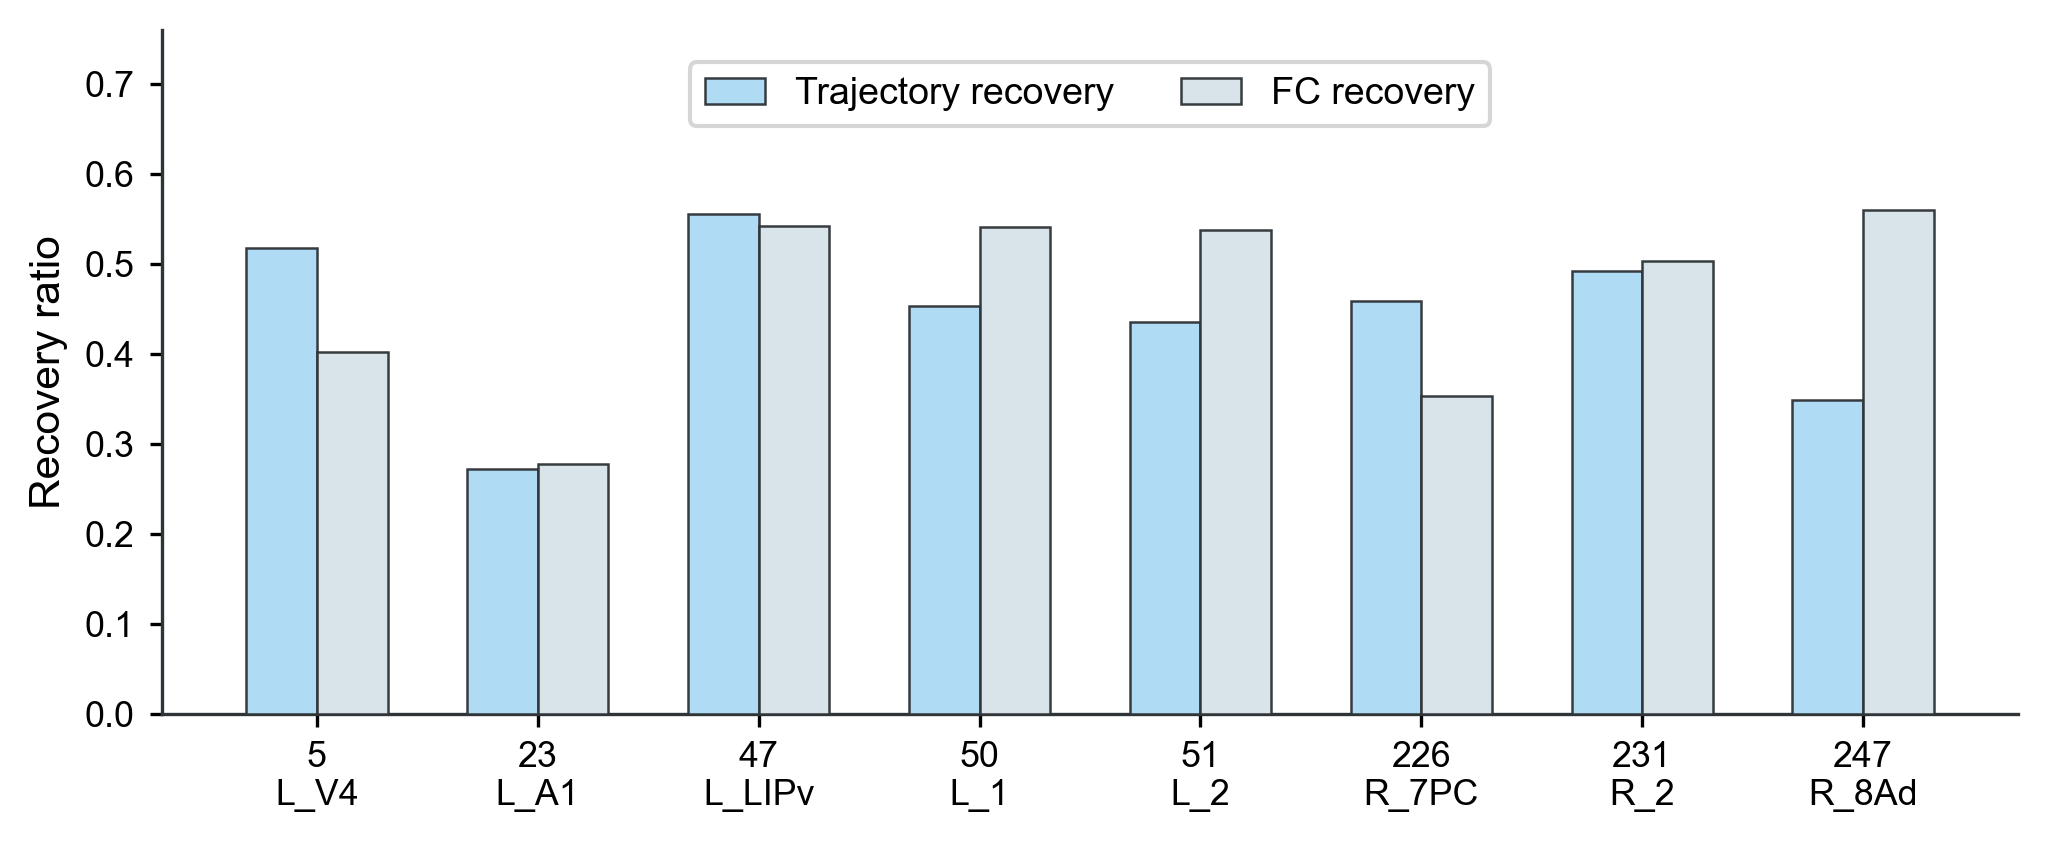

c:\Users\10193\Desktop\bibm_2026plot\paper_figures\fig3_lesion_node_robustness.pdf


In [22]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


ROOT = Path.cwd()
OUT_DIR = ROOT / "paper_figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcdefaults()
plt.rcParams.update({
    "savefig.dpi": 300,
    "figure.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 9,
    "axes.labelsize": 10.2,
    "axes.titlesize": 11.2,
    "xtick.labelsize": 8.6,
    "ytick.labelsize": 8.6,
    "legend.fontsize": 9,
    "axes.linewidth": 0.8,
})


def style_bar_axis(ax):
    ax.set_axisbelow(True)
    # ax.grid(axis="y", color="#EEF3F7", linewidth=0.8, zorder=0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#2F3437")
    ax.spines["bottom"].set_color("#2F3437")
    ax.tick_params(width=0.8, length=3, labelsize=8.6)


bar_colors = {
    "Trajectory recovery": "#ADDAF4",
    "FC recovery": "#D8E2EA",
}


robust_df = pd.read_csv(ROOT.parent / "results" / "grid_search" / "lesion_node_robustness_summary.csv")
plot_df = robust_df[robust_df["status"].eq("ok")].copy()
plot_df["label"] = plot_df.apply(lambda row: f"{int(row['lesion_idx'])}\n{row['lesion_name']}", axis=1)

fig, ax = plt.subplots(figsize=(6.8, 3.0))

x = np.arange(len(plot_df))
bar_width = 0.32
series = [
    ("Trajectory recovery", "traj_recovery", -bar_width / 2),
    ("FC recovery", "fc_recovery", bar_width / 2),
]

for label, col, offset in series:
    ax.bar(
        x + offset,
        plot_df[col].to_numpy(),
        bar_width,
        color=bar_colors[label],
        alpha=0.96,
        edgecolor="#2F3437",
        linewidth=0.6,
        label=label,
        zorder=3,
    )

# ax.axhline(0, color="#2F3437", linestyle="-", linewidth=0.8, zorder=2)
ax.set_xticks(x)
ax.set_xticklabels(plot_df["label"].tolist(), rotation=0)
ax.set_ylabel("Recovery ratio")
ax.set_ylim(0.0, max(0.76, float(plot_df[["traj_recovery", "fc_recovery"]].to_numpy().max()) + 0.18))
style_bar_axis(ax)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.50, 0.98),
    ncol=2,
    handlelength=1.6,
    columnspacing=1.8,
    frameon=True,
)
fig.subplots_adjust(left=0.085, right=0.995, top=0.95, bottom=0.19)

fig.savefig(OUT_DIR / "fig3_lesion_node_robustness.pdf", bbox_inches="tight")
plt.show()
print(OUT_DIR / "fig3_lesion_node_robustness.pdf")